In [8]:
# 0. 라이브러리 임포트

import json
import re
from konlpy.tag import Okt
from collections import Counter
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import font_manager, rc
from wordcloud import WordCloud

In [10]:
# Naver 검색 API 예제 코드 임포트
import urllib.request
import urllib.parse

import os
from dotenv import load_dotenv

import datetime
import json

load_dotenv() # .env 파일 로드

client_id = os.getenv("CLIENT_ID")
client_secret = os.getenv("CLIENT_SECRET")

import sys
from pathlib import Path
ch05_path = os.path.abspath(os.path.join(Path.cwd(), '../../ch05')) # 경로를 절대 경로로 변환

if ch05_path not in sys.path:
    sys.path.append(ch05_path) # 파이썬 모듈 검색 경로에 추가
    
from nvCrawler import getRequestUrl, getNaverSearch, getPostData, main

In [45]:
# 1. 데이터 수집
main() # 키워드에 대한 뉴스 기사를 1000건 가져와 json으로 저장함

inputFileName = '백엔드 개발자_naver_news'
data = json.loads(open(inputFileName + '.json', 'r', encoding = 'utf8').read())
print(data[0:50])

검색어를 입력하세요:  백엔드 개발자


[2026-11-03 18:24:07.794467] Url Request Success
[2026-11-03 18:24:09.475082] Url Request Success
[2026-11-03 18:24:11.128842] Url Request Success
[2026-11-03 18:24:12.792518] Url Request Success
[2026-11-03 18:24:14.469835] Url Request Success
[2026-11-03 18:24:16.103301] Url Request Success
[2026-11-03 18:24:17.732421] Url Request Success
[2026-11-03 18:24:19.392666] Url Request Success
[2026-11-03 18:24:21.082285] Url Request Success
[2026-11-03 18:24:22.807845] Url Request Success
HTTP Error 400: Bad Request
[2026-11-03 18:24:27.710465] Error for URL: https://naverapihub.apigw.ntruss.com/search/v1/news?query=%EB%B0%B1%EC%97%94%EB%93%9C%20%EA%B0%9C%EB%B0%9C%EC%9E%90&start=1001&display=100
전체 검색 : 15340 건
가져온 데이터 : 1000 건
백엔드 개발자_naver_news.json SAVED
[{'cnt': 1, 'description': '요청은 <b>백엔드</b>에서 다른 모델로 보내지는 방식을 뜻한다. 이후 일부 이용자는 앤트로픽이 제한된 사용자 집단을 상대로 새 모델을 비교 시험하는 A/B 테스트를 진행 중일 수 있다고 봤다. AI <b>개발자</b> 시카르는 복잡한... ', 'org_link': 'https://www.digitaltoday.co.kr/news/articleView.html?idx

In [46]:
# 2. 데이터 준비

# 2-1. 데이터 추출
titles = ''
for item in data:
    if 'title' in item.keys():
      raw = item['title']
      raw = re.sub(r'\[[^\]]+\]', '', raw) # 대괄호 안에 있는 내용 제거. ex. [생생 Job]
      raw = re.sub(r'<[^>]+>', '', raw) # 태그 제거. ex. <b>, </b>
      raw = re.sub(r'&[^;]+;', '', raw) # &quot; 제거.
      titles = titles + re.sub(r'[^\w]', ' ', raw) + '' # 유니코드, 숫자, 밑줄 아닌 거 찾아서 공백으로 대체(공백, 탭, 줄바꿈, 특수문자, 구두점, 하이픈 등이 걸림)
print(titles)

 비트코인 美 중간선거 영향은 테슬라 사이버캡 국내 첫 전   클로드 페이블 5 5 GPT 6 2 아스트라 줄줄이 포착 최첨단 모델 나오나 유니트리는 투자로  BYD는 수출로  텐센트   퀄컴 스냅드래곤 X2 엘리트  GPU 드라이버 업데이트 후 AI 성능 최대 87     게임 클라이언트 프로그래머 C   엔진은 기본  50대 이후는   게임 개발 문턱 낮춘 AI  불가능을 가능하게 만들어주는 역할   쿠키    AI가 일하는 판 깐다 에이전트 앱부터 구글 TPU 보안까지 OCI   달라진 성장 방정식 AI시대  제약바이오 경쟁력 해외게임통신 592호  마리오의 아버지 미야모토 시게루 문화훈장    1년 다녔는데 프로젝트 책임지라네요  2030이 소규모 IT기업 떠나는   취업 문턱 낮춘다 경복대 소프트웨어융합과  채용설명회 현장면접 진   배민   주문 후 배달 에서  주문 전 예측 으로   AI가 바꾸는 배달시   오픈랩스  온프레미스형 AI 개발도구  누비다  출시개발자 꿈꾸는 자녀 괜찮을까  네이버 리더가 8년 만에 다시 쓴 진로 조   인터넷 끊긴 사내망에서 AI가 개발까지  오픈랩스  누비다  설치형 론칭전국 대학생 420명 AI 앱 개발 도전   AI 앱 해커톤   이틀 만에 AI 앱   오픈랩스   누비다  폐쇄형 모델 출시 명세서 기반  기업 AI 코딩  혁   배민  AI 데이터로 배달 혁신 속도 우아콘서 미래 배달 청사진 공개우아한형제들   우아한테크콘퍼런스2026  개최 40여 개 세션 진행다이어트 과자 찾아줘 배민 AI  검색어 뜻까지 이해한다 제우스  흥행으로 한숨 돌린 컴투스  신작 퍼블리싱 AI 플랫폼으로    우아한형제들   우아한테크콘퍼런스  개최  심리스 시티  비전 제시배민  AI로 주문 배달 대기시간 줄인다    심리스 시티  비전 공개우아한형제들  테크콘퍼런스 성료    배민 기술 성과 공유배민   우아한테크콘퍼런스2026  개최 AI로 배달 기술 고도화 기다림 없는 배달을 향해   배민  AI 로봇으로  멈추지 않  

In [47]:
# 2-2. 명사 단어 추출

nlp = Okt()
titles_N = nlp.nouns(titles) # 명사만 뽑음. 중복 체크는 안함.
print(titles_N)

['비트코인', '중간', '선거', '영향', '테슬라', '사이버', '캡', '국내', '첫', '전', '클로드', '페이', '블', '아스트', '줄줄이', '포착', '최첨단', '모델', '유니', '트리', '투자', '수출', '텐센트', '퀄컴', '스냅드래곤', '엘리트', '드라이버', '업데이트', '후', '성능', '최대', '게임', '클라이언트', '프로그래머', '엔진', '기본', '이후', '게임', '개발', '문턱', '불가능', '역할', '쿠키', '일', '판', '에이전트', '앱', '구글', '보안', '성장', '방정식', '시대', '제약', '바이오', '경쟁력', '해외', '게임', '통신', '호', '마리오', '아버지', '모토', '시게루', '문화', '훈장', '프로젝트', '책임', '이', '소규모', '기업', '취업', '문턱', '경복대', '소프트웨어', '융합', '채용', '설명', '회', '현장', '면접', '진', '배민', '주문', '후', '배달', '주문', '전', '예측', '배달', '시', '오픈', '랩스', '프레', '미스', '개발', '도구', '누비', '출시', '개발자', '자녀', '네이버', '리더', '다시', '진로', '조', '인터넷', '망', '개발', '오픈', '랩스', '누비', '설치', '론칭', '전국', '대학생', '명', '앱', '개발', '도전', '앱', '해커', '톤', '이틀', '앱', '오픈', '랩스', '누비', '폐쇄형', '모델', '출시', '명세서', '기반', '기업', '코딩', '혁', '배민', '데이터', '배달', '혁신', '속도', '우아콘', '미래', '배달', '청사진', '공개', '형제', '테크', '콘퍼런스', '개최', '여', '개', '세션', '진행', '다이어트', '과자', '배민', '검색어', '뜻', '이해', '제우스', '흥행', '한숨',

In [48]:
count = Counter(titles_N)
print(count)

Counter({'게임': 430, '컴투스': 262, '플랫폼': 227, '개발': 201, '백엔드': 189, '오픈': 174, '하이브': 145, '액실': 118, '개최': 98, '서울': 87, '빌더스': 74, '출시': 71, '카카오': 71, '공개': 69, '개발자': 61, '모집': 61, '투자': 59, '해커': 57, '로': 57, '톤': 55, '기술': 54, '업': 52, '현대차': 51, '엑스': 50, '기아': 49, '기': 49, '시대': 48, '프티': 45, '채용': 43, '기업': 42, '배민': 41, '운영': 41, '전략': 41, '첫': 40, '테크': 40, '부트캠프': 38, '지원': 37, '인재': 36, '대표': 34, '코덱스': 33, '형제': 30, '나무': 30, '클래스': 30, '에이전트': 29, '캠퍼스': 29, '사': 28, '코딩': 27, '송재경': 27, '보안': 26, '특화': 25, '플러그인': 24, '개': 21, '리니지': 21, '배달': 20, '등': 20, '엔지니어': 20, '앱': 19, '기반': 19, '콘퍼런스': 19, '확대': 19, '서비스': 19, '결제': 19, '연': 19, '소개': 19, '인': 19, '서버': 18, '생태계': 18, '비트': 18, '육성': 18, '차세대': 18, '미래': 17, '취약점': 17, '제공': 17, '참가': 17, '노하우': 17, '서밋': 17, '도구': 16, '로봇': 16, '활용': 16, '한국': 16, '챗': 16, '홀딩스': 16, '코드': 16, '자산': 16, '디': 16, '멘토': 16, '협업': 15, '행사': 15, '교육': 15, '학기': 15, '개막': 15, '미리': 15, '국내': 14, '전': 14, '제시': 14, '도쿄': 14, '인프라': 1

In [49]:
word_count = dict()
for tag, counts in count.most_common(50): # 출현 횟수 기준 상위 50개 뽑
    if len(str(tag)) > 1: # 길이가 1보다 큰 것만(50개 중 일부 제거됨!!)
        word_count[tag] = counts
        print("%s : %d" % (tag, counts))

게임 : 430
컴투스 : 262
플랫폼 : 227
개발 : 201
백엔드 : 189
오픈 : 174
하이브 : 145
액실 : 118
개최 : 98
서울 : 87
빌더스 : 74
출시 : 71
카카오 : 71
공개 : 69
개발자 : 61
모집 : 61
투자 : 59
해커 : 57
기술 : 54
현대차 : 51
엑스 : 50
기아 : 49
시대 : 48
프티 : 45
채용 : 43
기업 : 42
배민 : 41
운영 : 41
전략 : 41
테크 : 40
부트캠프 : 38
지원 : 37
인재 : 36
대표 : 34
코덱스 : 33
형제 : 30
나무 : 30
클래스 : 30
에이전트 : 29
캠퍼스 : 29
코딩 : 27
송재경 : 27
보안 : 26
특화 : 25


In [39]:
font_path = "c:/Windows/fonts/malgun.ttf" # 기본적인 폰트 위치
font_name = font_manager.FontProperties(fname = font_path).get_name()
matplotlib.rc('font', family = font_name) # font 속성 지정

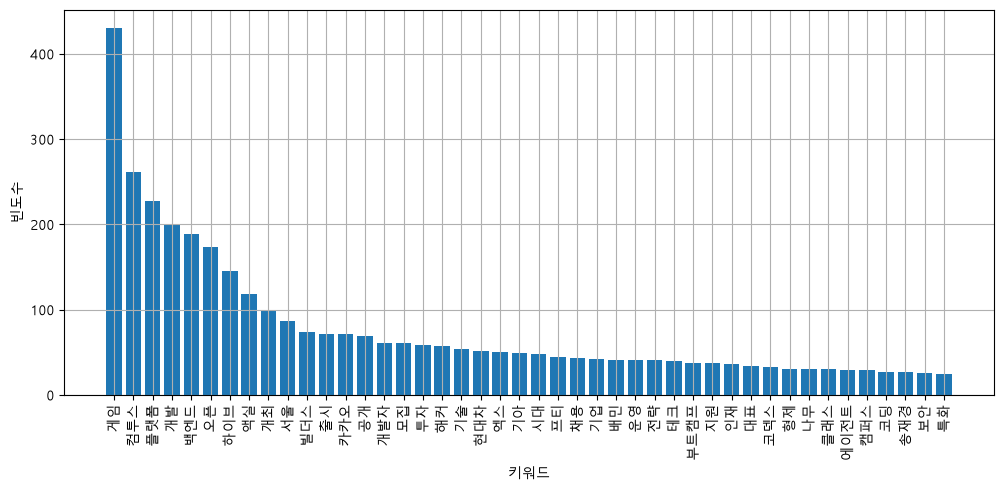

In [50]:
plt.figure(figsize = (12, 5))
plt.xlabel('키워드') # 한굴은 폰트 지정 안되면 꺠짐. 위에서 폰트 지정한 이유
plt.ylabel('빈도수')
plt.grid(True)
sorted_Keys = sorted(word_count, key = word_count.get, reverse = True)
sorted_Values = sorted(word_count.values(), reverse = True)
plt.bar(range(len(word_count)), sorted_Values, align = 'center')
plt.xticks(range(len(word_count)), list(sorted_Keys), rotation = 'vertical')
plt.savefig('백엔드 개발자 빈도수 bar_chart.png')
plt.show()

type: <class 'wordcloud.wordcloud.WordCloud'>



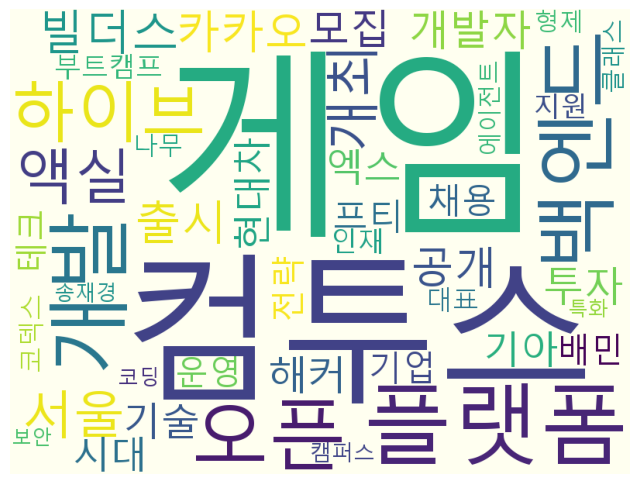

In [51]:
wc = WordCloud(font_path, background_color = 'ivory', width = 800, height = 600)
cloud = wc.generate_from_frequencies(word_count)
print(f'type: {type(cloud)}\n')
plt.figure(figsize = (8,8))
plt.imshow(cloud)
plt.axis('off')
cloud.to_file(inputFileName + '_cloud.jpg')
plt.show()